# Histogram Processing: Perbaikan Citra Low-Light CCTV

### Identitas Mahasiswa
- **Nama Lengkap:** `Oktavianus Samuel Minarto`
- **NIM:** `245150200111043`

---

### Deskripsi Kasus
Peningkatan kualitas citra CCTV low-light menggunakan Histogram Equalization (manual) dan CLAHE.


## <a id="bagian-1"></a>Bagian 1: Import Library & Persiapan Lingkungan

Pada tahap ini, kita mengimpor pustaka dasar yang diperbolehkan:
- `cv2` (OpenCV): Digunakan untuk pembacaan citra grayscale, fungsi built-in `cv2.equalizeHist()` untuk validasi, dan `cv2.createCLAHE()`.
- `numpy`: Digunakan untuk komputasi matriks citra, penghitungan histogram frekuensi, nilai kumulatif (CDF), dan Lookup Table (LUT).
- `matplotlib.pyplot`: Digunakan untuk visualisasi citra dan plot histogram sesuai standar visualisasi jurnal/PPT.
- `pathlib.Path`, `os`: Digunakan untuk manajemen berkas input dan direktori penyimpanan output.


In [1]:
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

OUTPUT_DIR = Path("hasil_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## <a id="bagian-2"></a>Bagian 2: Pemuatan Citra Input Low-Light

Sesuai **Butir 1 Tugas**, kita membaca citra kondisi minim cahaya (*low-light*) dalam mode **grayscale** menggunakan flag `cv2.IMREAD_GRAYSCALE`.

Citra grayscale merepresentasikan intensitas cahaya pada setiap koordinat piksel $(x, y)$ dalam rentang 8-bit integer:
$$f(x, y) \in [0, 255]$$
di mana nilai 0 adalah hitam sempurna (tidak ada cahaya) dan 255 adalah putih terang.


In [2]:
possible_paths = [
    Path("../assets/sample1.png"),
    Path("assets/sample1.png"),
    Path("sample1.png"),
]

img_path = None
for p in possible_paths:
    if p.exists():
        img_path = p
        break

if img_path is None:
    raise FileNotFoundError("Citra sample1.png tidak ditemukan.")

img_gray = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
if img_gray is None:
    raise ValueError(f"Gagal membaca citra dari {img_path}")

tinggi, lebar = img_gray.shape
total_piksel = tinggi * lebar
min_val = int(img_gray.min())
max_val = int(img_gray.max())
mean_val = float(img_gray.mean())
std_val = float(img_gray.std())

print(f"Dimensi citra : {lebar}x{tinggi} px ({total_piksel:,} piksel)")
print(f"Intensitas    : min={min_val}, max={max_val}, mean={mean_val:.2f}, std={std_val:.2f}")


Dimensi citra : 1600x1440 px (2,304,000 piksel)
Intensitas    : min=0, max=255, mean=30.11, std=36.49


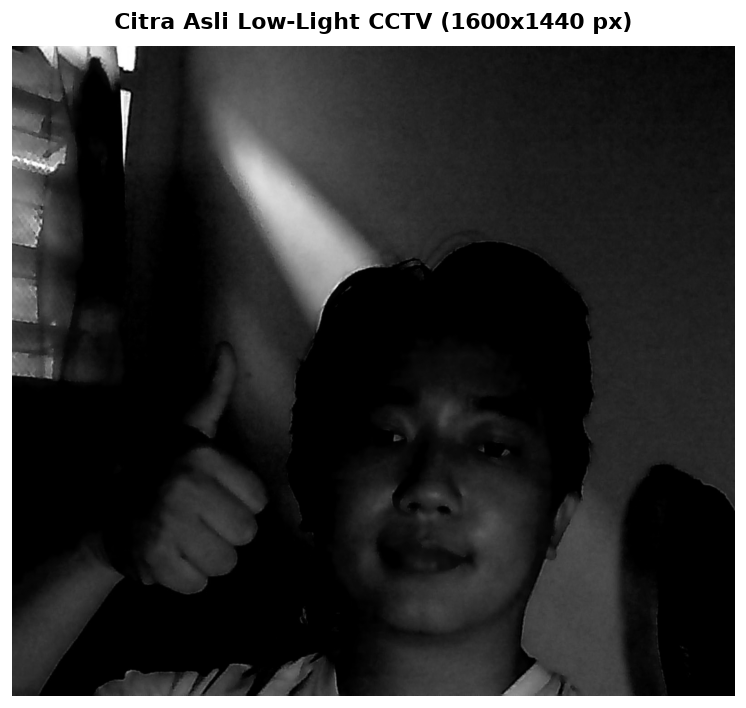

In [3]:
# Menampilkan citra asli
plt.figure(figsize=(8, 6))
plt.imshow(img_gray, cmap='gray', vmin=0, vmax=255)
plt.title(f"Citra Asli Low-Light CCTV ({lebar}x{tinggi} px)", fontsize=13, fontweight='bold', pad=10)
plt.axis('off')
plt.tight_layout()
plt.show()


## <a id="bagian-3"></a>Bagian 3: Analisis & Visualisasi Histogram Citra Asli

Sesuai **Butir 2 Tugas** dan materi Slide 7–11 pada PPT:
- **Histogram citra** adalah diagram yang menggambarkan frekuensi kemunculan setiap nilai intensitas ($r_k$) yang muncul di seluruh piksel citra:
  $$h(r_k) = n_k, \quad \text{untuk } k = 0, 1, 2, \dots, L-1$$
  di mana $r_k$ adalah tingkat keabuan ke-$k$ ($0 \le r_k \le 255$ untuk 8-bit), dan $n_k$ adalah banyaknya piksel yang memiliki intensitas $r_k$.
- **Normalisasi histogram** (Slide 11 PPT) menyatakan estimasi probabilitas kemunculan tingkat keabuan $r_k$:
  $$p(r_k) = \frac{n_k}{MN}, \quad \sum_{k=0}^{L-1} p(r_k) = 1$$


Piksel intensitas < 50: 1,848,038 (80.21%)


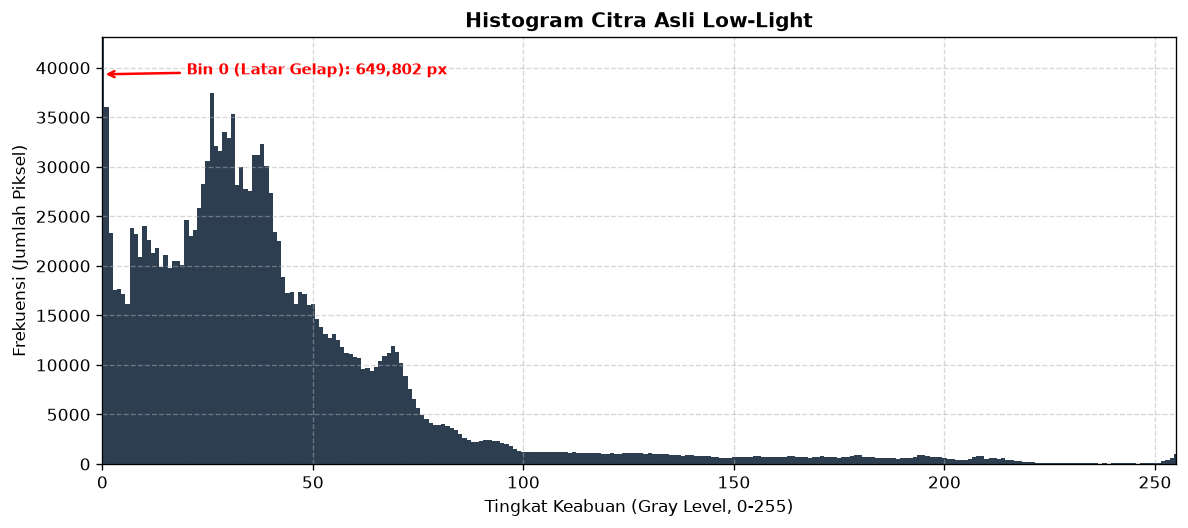

In [4]:
hist_original = np.bincount(img_gray.ravel(), minlength=256)
gray_levels = np.arange(256)

max_content_freq = hist_original[1:].max() if len(hist_original) > 1 else hist_original.max()
piksel_sangat_gelap = int(np.sum(hist_original[:50]))
persentase_gelap = (piksel_sangat_gelap / total_piksel) * 100

print(f"Piksel intensitas < 50: {piksel_sangat_gelap:,} ({persentase_gelap:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(gray_levels, hist_original, color='#2c3e50', width=1.0, edgecolor='none')
ax.set_xlim([0, 255])
ax.set_ylim([0, max_content_freq * 1.15])
ax.set_title("Histogram Citra Asli Low-Light", fontsize=12, fontweight='bold')
ax.set_xlabel("Tingkat Keabuan (Gray Level, 0-255)")
ax.set_ylabel("Frekuensi (Jumlah Piksel)")
ax.grid(True, linestyle='--', alpha=0.5)

ax.annotate(
    f"Bin 0 (Latar Gelap): {hist_original[0]:,} px",
    xy=(0, max_content_freq * 1.05),
    xytext=(20, max_content_freq * 1.05),
    arrowprops=dict(arrowstyle="->", color="red", lw=1.5),
    fontsize=9, color="red", fontweight="bold"
)

plt.tight_layout()
plt.show()


### Interpretasi Karakteristik Citra Input:
1. **Histogram Menumpuk di Sisi Kiri (*Low-Key Image*)**: Sesuai konsep pada Slide 10 dan Slide 27 PPT, citra minim cahaya (*low-light*) dicirikan oleh histogram yang terkonsentrasi rapat pada spektrum gelap ($r_k < 50$).
2. **Rentang Dinamis Sangat Sempit (*Low Contrast*)**: Intensitas pada rentang menengah (*midtone*) dan terang (*highlight*) hampir tidak memiliki piksel. Hal ini menyebabkan perbedaan intensitas antar-objek (seperti batas objek, kontur dinding, atau wajah) menjadi sangat kecil dan sulit dibedakan oleh mata manusia.
3. **Kebutuhan Perbaikan**: Citra sangat memerlukan peregangan rentang dinamis agar detail yang tersembunyi pada area gelap dapat diangkat dan terlihat jelas oleh petugas keamanan CCTV.


## <a id="bagian-4"></a>Bagian 4: Implementasi Manual Histogram Equalization

Sesuai **Butir 3 Tugas**, kita mengimplementasikan Histogram Equalization secara **MANUAL** tanpa memanggil `cv2.equalizeHist()`, dengan mengikuti tahapan pada slide **'Proses Perhitungan Manual Histogram Equalization'** (PPT Slide 14, 16–17, dan 23).

### Landasan Teori & Rumus Matematis:
Tujuan dari Histogram Equalization adalah menghasilkan citra baru dengan histogram yang tersebar merata (*uniform*) di seluruh rentang tingkat keabuan $[0, L-1]$.

1. **Langkah A: Menghitung Histogram Frekuensi ($n_k$)**
   Menghitung frekuensi kemunculan setiap tingkat keabuan $r_k$ untuk $k = 0, 1, \dots, L-1$ (di mana $L = 256$):
   $$n_k = \text{jumlah piksel dengan nilai intensitas } k$$

2. **Langkah B: Menghitung Cumulative Distribution Function (CDF)**
   Menghitung jumlah kumulatif frekuensi piksel dari level 0 hingga level $k$:
   $$CDF(k) = \sum_{j=0}^{k} n_j$$

3. **Langkah C: Normalisasi dan Pemetaan Intensitas ($s_k$)**
   - Berdasarkan **PPT Slide 14 & 17**, formula teoritis dasarnya adalah:
     $$s_k = \text{round}\left( \frac{CDF(k)}{MN} \times (L - 1) \right)$$
   - Pada citra digital diskrit minim cahaya yang memiliki sejumlah besar piksel bernilai 0 (kegelapan mutlak), jika kita menggunakan formula dasar di atas tanpa mengoreksi nilai minimum kumulatif ($CDF_{min}$), maka piksel tergelap (0) akan langsung terpetakan ke nilai abu-abu terang ($s_0 = \frac{n_0}{MN} \times 255$), sehingga citra menjadi berkabut (*washed-out grey*).
   - Oleh karena itu, pada **PPT Slide 23** dan standar implementasi OpenCV `cv2.equalizeHist()`, diterapkan normalisasi dengan mengeliminasi offset $CDF_{min}$ (nilai CDF non-nol pertama):
     $$s_k = \text{round}\left( \frac{CDF(k) - CDF_{min}}{MN - CDF_{min}} \times (L - 1) \right)$$
     Formula ini menjamin bahwa intensitas terendah yang ada pada citra input akan terpetakan tepat ke 0 (hitam pekat) dan intensitas tertinggi terpetakan tepat ke 255 (putih penuh), menghasilkan peregangan kontras yang optimal.

4. **Langkah D: Pemetaan Citra Baru Menggunakan Lookup Table (LUT)**
   Nilai $s_k$ yang telah dibulatkan dijadikan tabel pemetaan (*Lookup Table*) untuk mengubah setiap piksel citra input $I_{in}(x, y)$ menjadi citra hasil $I_{out}(x, y)$:
   $$I_{out}(x, y) = s_k[I_{in}(x, y)]$$


In [5]:
def manual_histogram_equalization(image):
    """Implementasi manual Histogram Equalization sesuai rumus CDF terkoreksi."""
    h, w = image.shape
    total_pixels = h * w
    L = 256

    nk = np.bincount(image.ravel(), minlength=L)
    cdf = np.cumsum(nk)

    cdf_min_indices = np.where(cdf > 0)[0]
    cdf_min = cdf[cdf_min_indices[0]]

    denom = total_pixels - cdf_min
    if denom == 0:
        sk_unrounded = np.zeros(L, dtype=np.float64)
        lut = np.zeros(L, dtype=np.uint8)
    else:
        sk_unrounded = ((cdf - cdf_min) / denom) * (L - 1)
        lut = np.round(sk_unrounded).astype(np.uint8)

    equalized_image = lut[image]
    return equalized_image, nk, cdf, sk_unrounded, lut

img_he_manual, nk_orig, cdf, sk_unrounded, lut = manual_histogram_equalization(img_gray)
print(f"HE Manual output range: [{img_he_manual.min()}, {img_he_manual.max()}], mean={img_he_manual.mean():.2f}")


HE Manual output range: [0, 255], mean=92.72


In [6]:
print(f"{'Gray Level (k)':<15} {'nk':<10} {'CDF':<10} {'sk (Ternormalisasi)':<20} {'sk (Dibulatkan)':<15}")
print("-" * 70)
for k in range(10):
    print(f"{k:<15} {nk_orig[k]:<10} {cdf[k]:<10} {sk_unrounded[k]:<20.4f} {lut[k]:<15}")


Gray Level (k)  nk         CDF        sk (Ternormalisasi)  sk (Dibulatkan)
----------------------------------------------------------------------
0               649802     649802     0.0000               0              
1               36056      685858     5.5581               6              
2               23336      709194     9.1555               9              
3               17533      726727     11.8582              12             
4               17677      744404     14.5832              15             
5               17112      761516     17.2211              17             
6               16118      777634     19.7057              20             
7               23866      801500     23.3847              23             
8               23195      824695     26.9603              27             
9               20870      845565     30.1775              30             


## <a id="bagian-5"></a>Bagian 5: Validasi Hasil Manual vs `cv2.equalizeHist()`

Sesuai **Butir 4 Tugas**, kita memvalidasi kebenaran implementasi manual dengan membandingkannya secara langsung terhadap hasil pustaka bawaan `cv2.equalizeHist()` pada citra yang sama.

Metrik evaluasi yang digunakan adalah **Mean Absolute Difference (MAD)**:
$$MAD = \frac{1}{MN} \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} |I_{manual}(x, y) - I_{opencv}(x, y)|$$

Selain itu, kita juga menghitung:
- **Maximum Absolute Difference**: $\max |I_{manual} - I_{opencv}|$
- **Persentase Piksel Identik**: Persentase jumlah piksel yang bernilai tepat sama antara kedua citra.


In [7]:
img_he_cv2 = cv2.equalizeHist(img_gray)
selisih_matriks = np.abs(img_he_manual.astype(np.float64) - img_he_cv2.astype(np.float64))

mad = np.mean(selisih_matriks)
max_diff = np.max(selisih_matriks)
jumlah_beda = np.count_nonzero(selisih_matriks)

print(f"Mean Absolute Difference (MAD) : {mad:.8f}")
print(f"Maksimum Selisih Piksel        : {max_diff}")
print(f"Jumlah Piksel Berbeda          : {jumlah_beda} dari {img_gray.size} piksel")
print(f"Status Validasi: {'IDENTIK dengan cv2.equalizeHist()' if mad == 0.0 else 'Berbeda'}")


Mean Absolute Difference (MAD) : 0.00000000
Maksimum Selisih Piksel        : 0.0
Jumlah Piksel Berbeda          : 0 dari 2304000 piksel
Status Validasi: IDENTIK dengan cv2.equalizeHist()


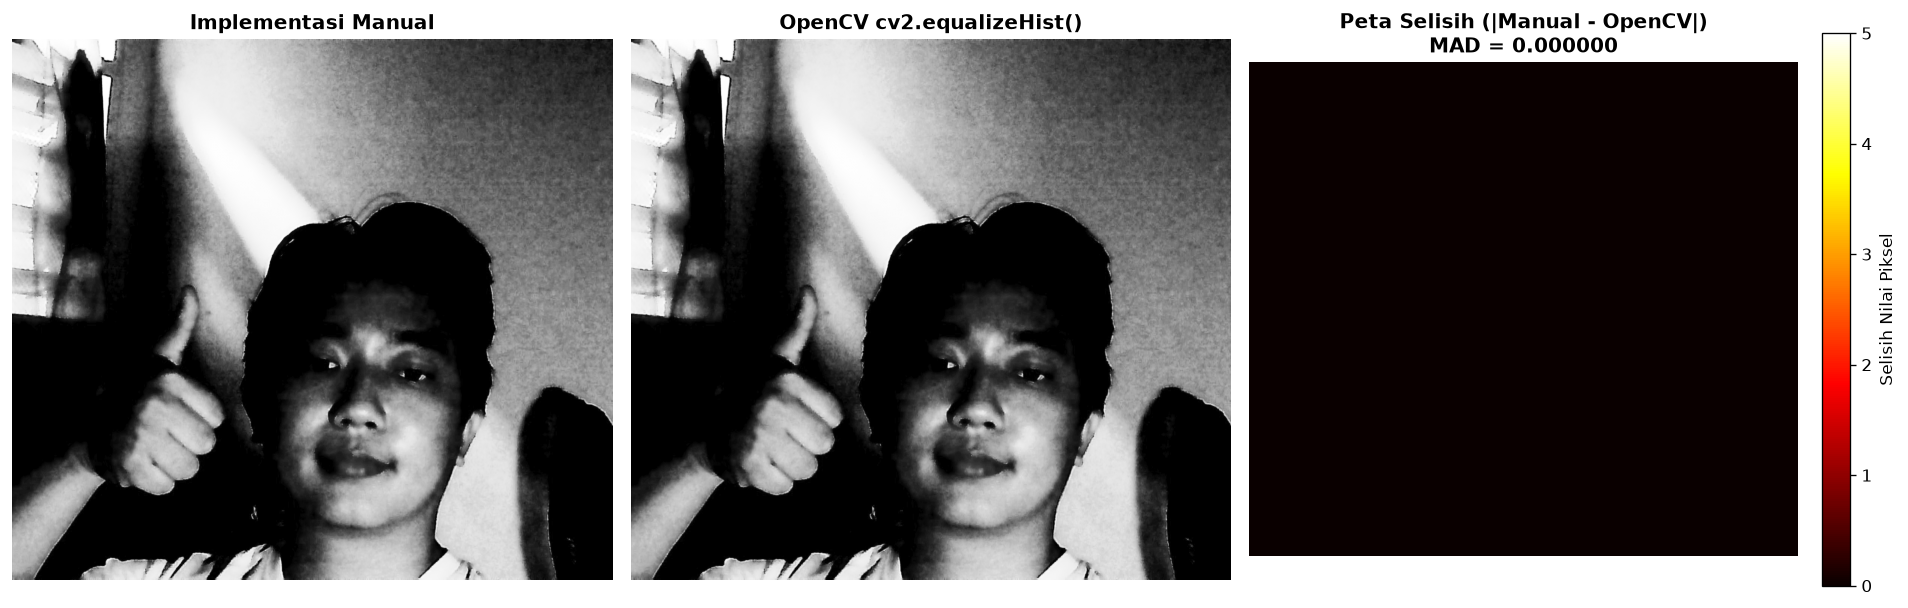

In [8]:
# Visualisasi perbandingan Manual vs OpenCV beserta Difference Map
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(img_he_manual, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Implementasi Manual", fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(img_he_cv2, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("OpenCV cv2.equalizeHist()", fontsize=12, fontweight='bold')
axes[1].axis('off')

# Peta selisih (|Manual - OpenCV|)
im_diff = axes[2].imshow(selisih_matriks, cmap='hot', vmin=0, vmax=5)
axes[2].set_title(f"Peta Selisih (|Manual - OpenCV|)\nMAD = {mad:.6f}", fontsize=12, fontweight='bold')
axes[2].axis('off')
cbar = plt.colorbar(im_diff, ax=axes[2], fraction=0.046, pad=0.04)
cbar.set_label("Selisih Nilai Piksel")

plt.tight_layout()
plt.show()


## <a id="bagian-6"></a>Bagian 6: Implementasi CLAHE dengan Eksplorasi Multi-Parameter

Sesuai **Butir 5 Tugas** dan materi PPT Slide 21–23:
- **Kelemahan Histogram Equalization (HE) Global**:
  HE menerapkan fungsi transformasi yang seragam ke seluruh citra. Pada citra CCTV low-light dengan latar belakang gelap yang dominan, HE menyebabkan **overenhancement** (kontras menjadi terlalu kasar/ekstrem) dan memicu **noise amplification** (derau sensor pada area gelap ikut terangkat dan merusak kualitas citra).
- **Konsep CLAHE (*Contrast Limited Adaptive Histogram Equalization*)**:
  1. **Divide (Tiling)**: Citra dibagi menjadi blok-blok lokal kecil yang disebut *tiles* (misal $8 \times 8$ atau $16 \times 16$).
  2. **Contrast Limiting (Clipping)**: Pada setiap tile, puncak histogram yang melebihi nilai ambang `clipLimit` dipotong, dan piksel yang terpotong didistribusikan merata ke seluruh bin histogram tile tersebut. Ini mencegah amplifikasi noise pada area homogen.
  3. **Local Histogram Equalization**: Dilakukan equalization secara independen pada masing-masing tile.
  4. **Bilinear Interpolation**: Nilai piksel antar-tile digabungkan menggunakan interpolasi bilinear untuk menghilangkan efek batas kotak (*checkerboard artifact*).

Kita menguji **4 kombinasi parameter** (melebihi syarat minimal 2 kombinasi) untuk menganalisis pengaruh parameter `clipLimit` dan `tileGridSize`:
- **Kombinasi 1 (Standar Seimbang)**: `clipLimit = 2.0`, `tileGridSize = (8, 8)`
- **Kombinasi 2 (Kontras Agresif)**: `clipLimit = 4.0`, `tileGridSize = (8, 8)`
- **Kombinasi 3 (Tile Grid Lebih Besar)**: `clipLimit = 2.0`, `tileGridSize = (16, 16)`
- **Kombinasi 4 (Konservatif Rendah Derau)**: `clipLimit = 1.0`, `tileGridSize = (8, 8)`


In [9]:
daftar_kombinasi = [
    {"label": "Kombinasi 1 (clip=2.0, tile=8x8)", "clip": 2.0, "tile": (8, 8), "keterangan": "Standar Seimbang"},
    {"label": "Kombinasi 2 (clip=4.0, tile=8x8)", "clip": 4.0, "tile": (8, 8), "keterangan": "Kontras Tinggi"},
    {"label": "Kombinasi 3 (clip=2.0, tile=16x16)", "clip": 2.0, "tile": (16, 16), "keterangan": "Tile Lebih Halus"},
    {"label": "Kombinasi 4 (clip=1.0, tile=4x4)", "clip": 1.0, "tile": (4, 4), "keterangan": "Rendah Noise"},
]

hasil_clahe = []
for config in daftar_kombinasi:
    clahe_obj = cv2.createCLAHE(clipLimit=config["clip"], tileGridSize=config["tile"])
    img_res = clahe_obj.apply(img_gray)
    hasil_clahe.append({
        "label": config["label"],
        "clip": config["clip"],
        "tile": config["tile"],
        "keterangan": config["keterangan"],
        "image": img_res,
        "mean": float(img_res.mean()),
        "std": float(img_res.std())
    })

print(f"{'Konfigurasi':<35} {'Min':<6} {'Max':<6} {'Mean':<8} {'Std':<8}")
print("-" * 65)
for item in hasil_clahe:
    im = item["image"]
    print(f"{item['label']:<35} {im.min():<6} {im.max():<6} {im.mean():<8.2f} {im.std():<8.2f}")


Konfigurasi                         Min    Max    Mean     Std     
-----------------------------------------------------------------
Kombinasi 1 (clip=2.0, tile=8x8)    1      255    51.93    51.13   
Kombinasi 2 (clip=4.0, tile=8x8)    1      255    63.93    58.81   
Kombinasi 3 (clip=2.0, tile=16x16)  1      255    47.07    45.98   
Kombinasi 4 (clip=1.0, tile=4x4)    1      255    44.19    45.50   


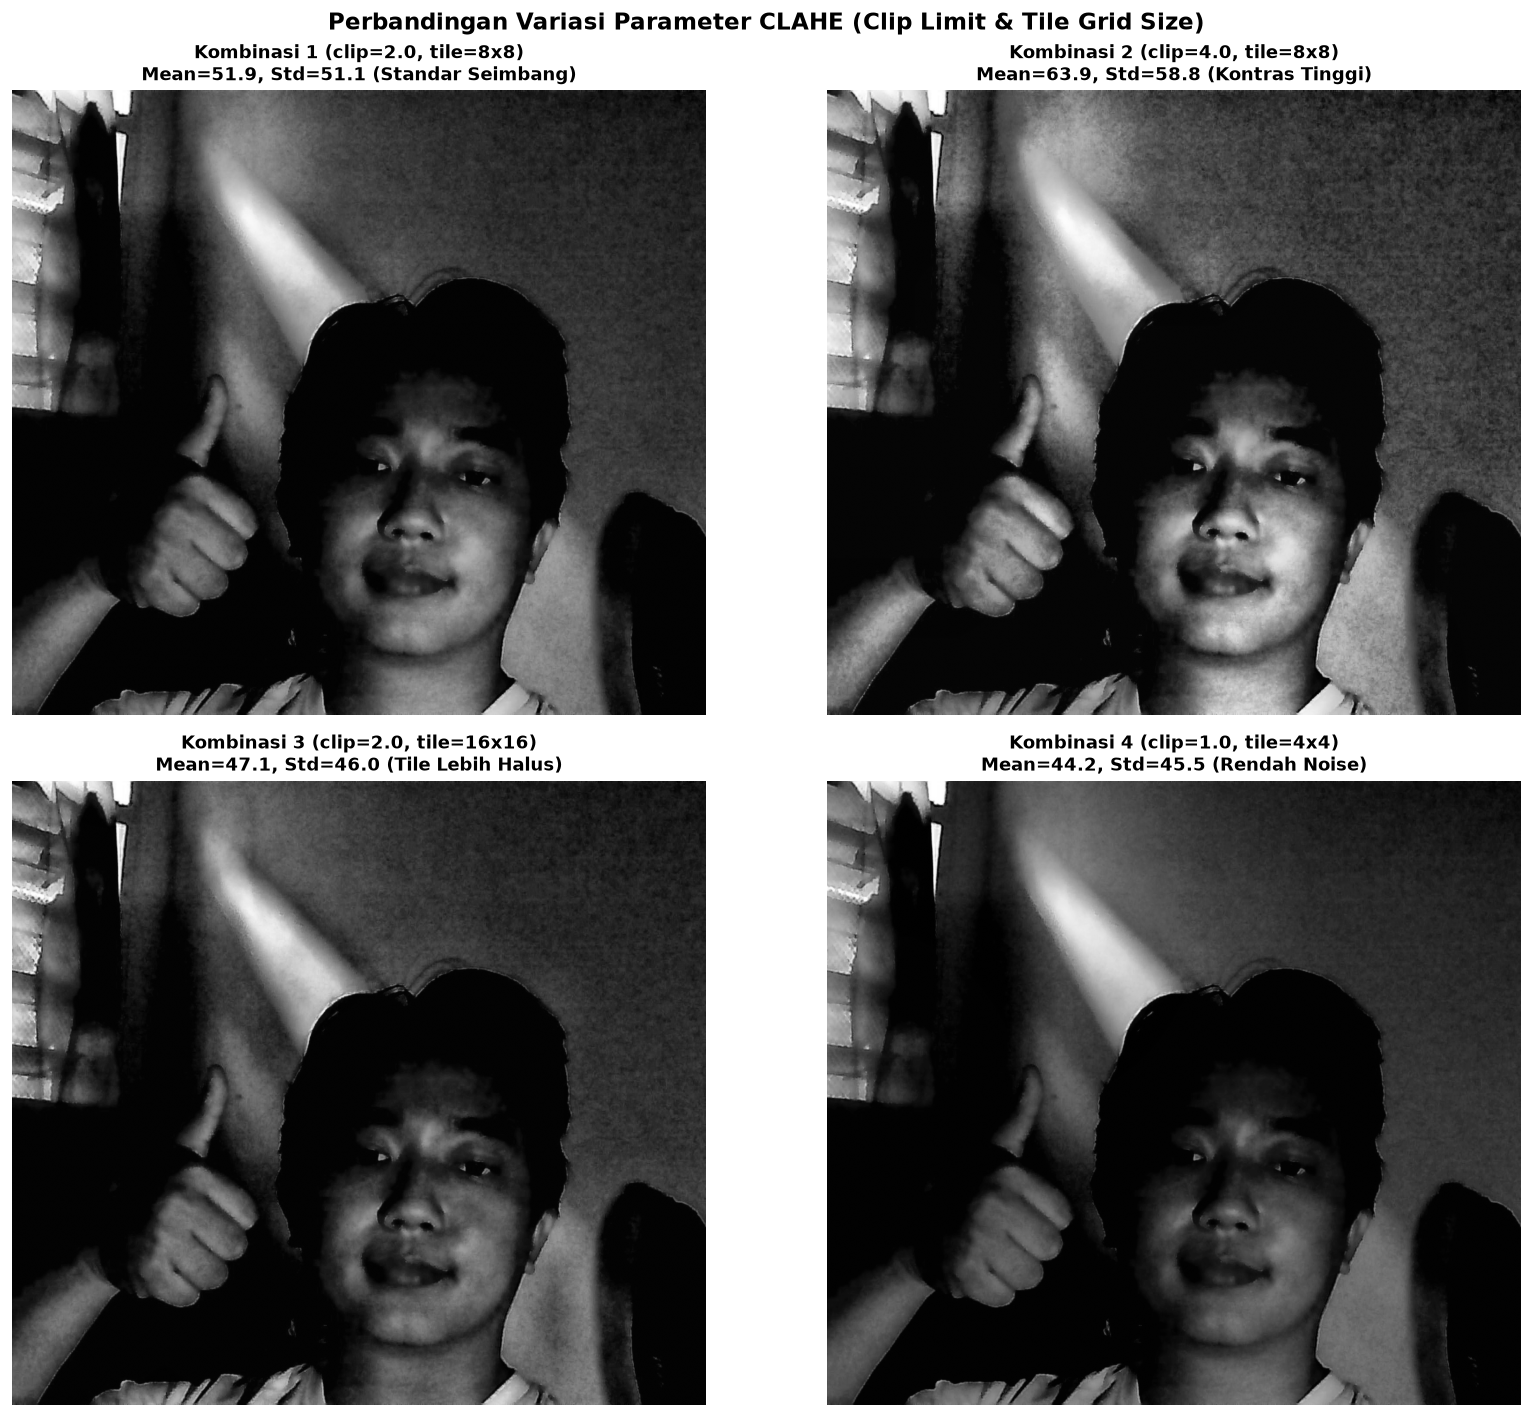

In [10]:
# Visualisasi perbandingan keempat kombinasi parameter CLAHE
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for idx, ax in enumerate(axes.flat):
    data = hasil_clahe[idx]
    ax.imshow(data["image"], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"{data['label']}\nMean={data['mean']:.1f}, Std={data['std']:.1f} ({data['keterangan']})", 
                 fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle("Perbandingan Variasi Parameter CLAHE (Clip Limit & Tile Grid Size)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### Analisis Parameter CLAHE:
1. **Pengaruh `clipLimit`**:
   - Nilai `clipLimit` menentukan batas maksimum pemotongan histogram lokal.
   - Pada `clipLimit = 4.0`, kontras lokal sangat kuat dan citra lebih cerah, namun derau (*sensor noise*) di area bayangan mulai terlihat teramplifikasi menjadi bintik-bintik kasar.
   - Pada `clipLimit = 1.0`, pembatasan kontras sangat ketat sehingga peningkatan detail pada area gelap kurang signifikan.
   - Nilai `clipLimit = 2.0` memberikan rasio kontras terhadap noise (*contrast-to-noise ratio*) yang paling seimbang.
2. **Pengaruh `tileGridSize`**:
   - Pada ukuran tile $(8, 8)$, citra dibagi menjadi 64 region lokal. Ukuran ini sangat efektif menangkap variasi pencahayaan mikro lokal.
   - Pada ukuran tile $(16, 16)$, setiap tile mencakup area yang lebih luas, sehingga peningkatan detail lokal menjadi lebih samar dan mendekati sifat global HE.


## <a id="bagian-7"></a>Bagian 7: Tampilan Berdampingan 3 Citra + 3 Histogram

Sesuai **Butir 6 Tugas** dan tampilan slide 30 PPT (*'Low-Light Image Enhancement'*), kita menampilkan dan menyimpan dalam satu figure terpadu ($2 \times 3$ subplots):
1. **Baris Atas (Citra)**:
   - (a) Citra Asli (*Low-Light CCTV*)
   - (b) Hasil Histogram Equalization (Global HE)
   - (c) Hasil CLAHE Terpilih (`clipLimit=2.0, tileGridSize=(8,8)`)
2. **Baris Bawah (Histogram)**:
   - (a) Histogram Citra Asli
   - (b) Histogram Hasil Histogram Equalization
   - (c) Histogram Hasil CLAHE


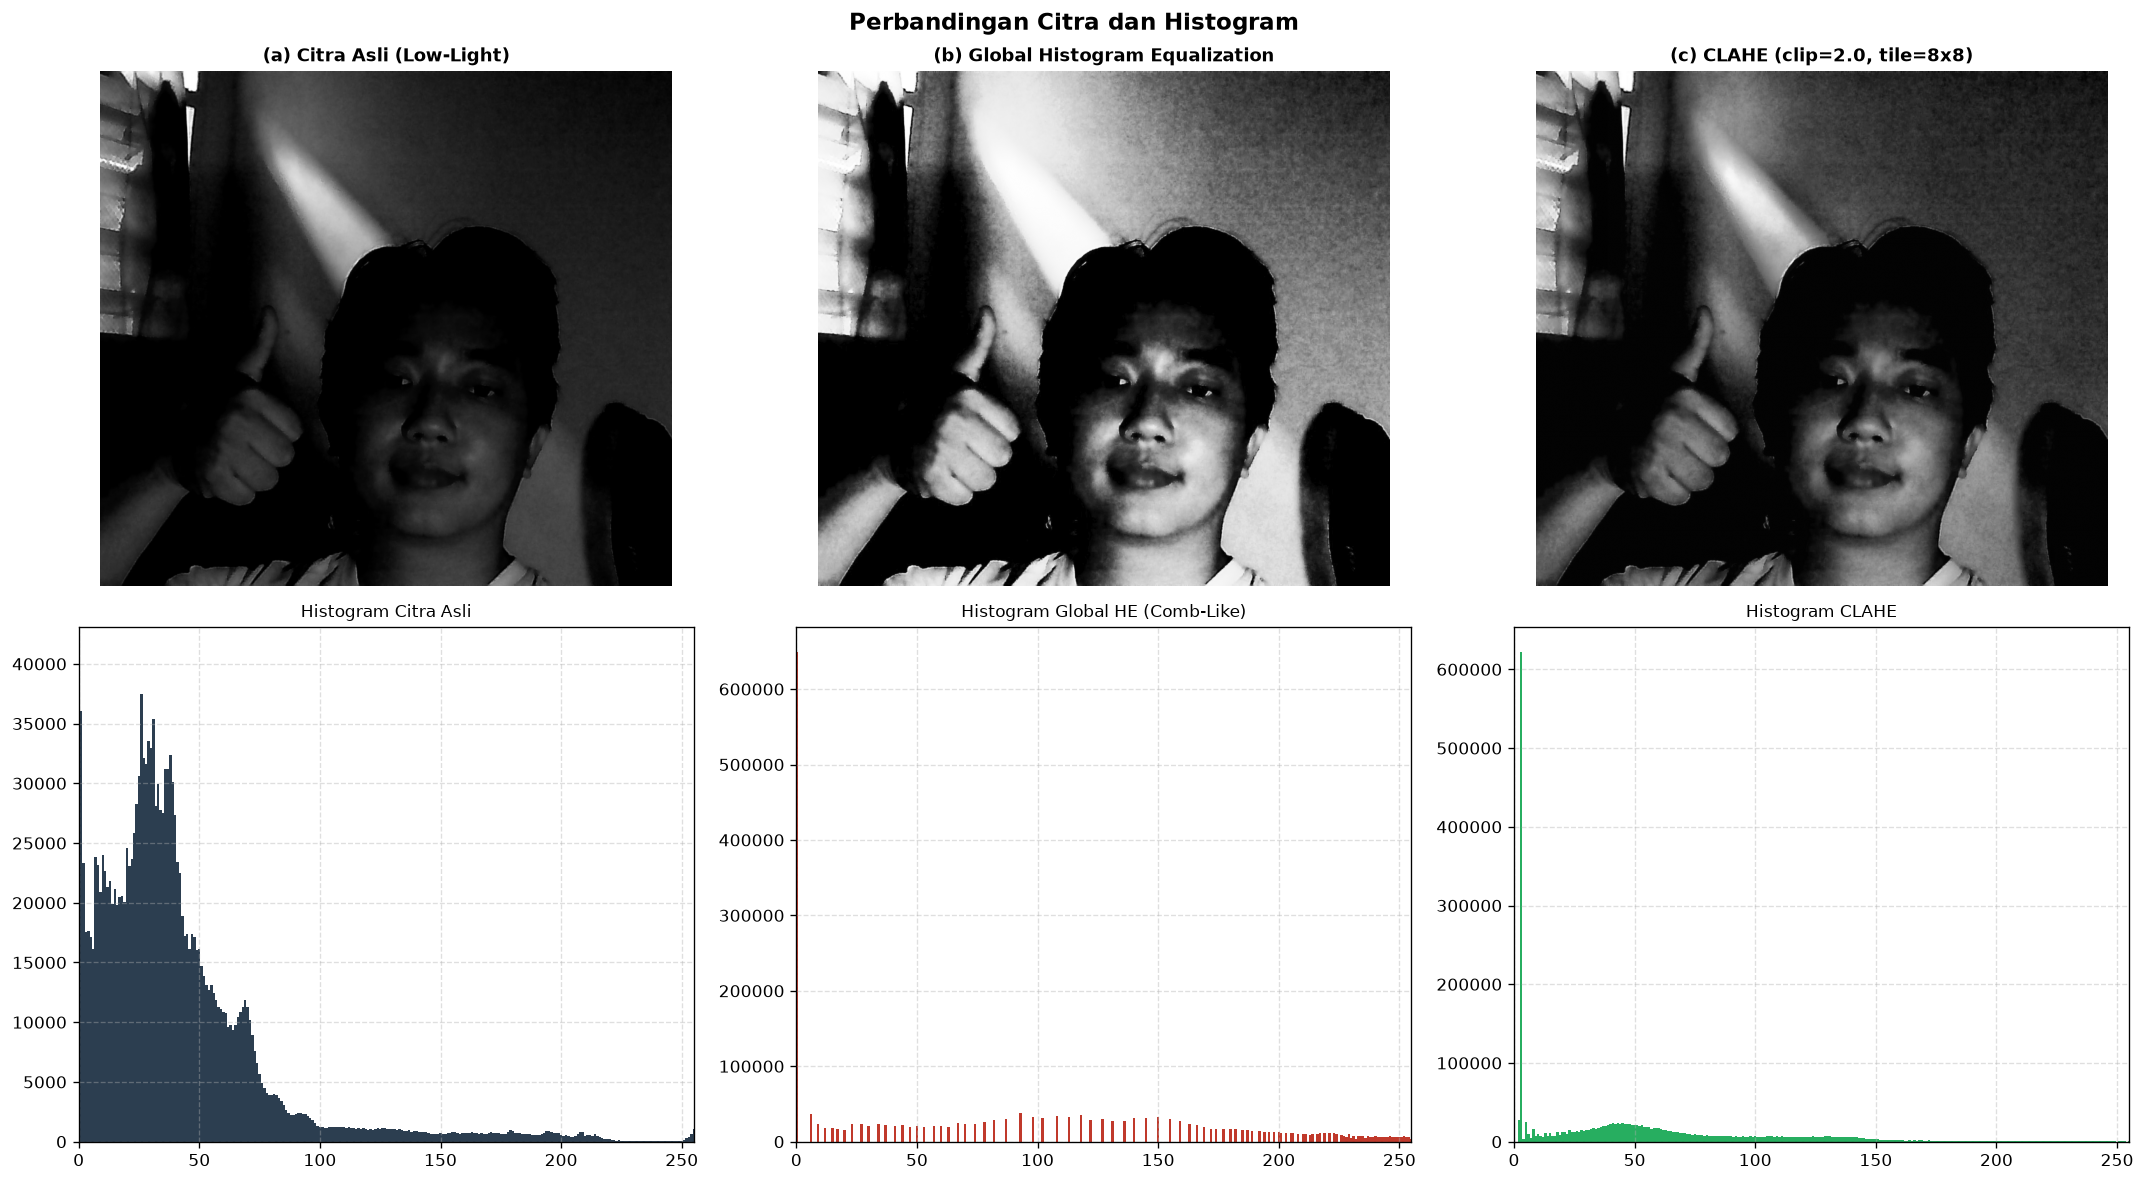

Gambar disimpan: hasil_output/perbandingan_histogram_processing.png


In [11]:
best_clahe = hasil_clahe[0]["image"]

h_orig = np.bincount(img_gray.ravel(), minlength=256)
h_he = np.bincount(img_he_manual.ravel(), minlength=256)
h_clahe = np.bincount(best_clahe.ravel(), minlength=256)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0, 0].set_title("(a) Citra Asli (Low-Light)", fontsize=11, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(img_he_manual, cmap='gray', vmin=0, vmax=255)
axes[0, 1].set_title("(b) Global Histogram Equalization", fontsize=11, fontweight='bold')
axes[0, 1].axis('off')

axes[0, 2].imshow(best_clahe, cmap='gray', vmin=0, vmax=255)
axes[0, 2].set_title("(c) CLAHE (clip=2.0, tile=8x8)", fontsize=11, fontweight='bold')
axes[0, 2].axis('off')

gl = np.arange(256)
axes[1, 0].bar(gl, h_orig, color='#2c3e50', width=1.0)
axes[1, 0].set_title("Histogram Citra Asli", fontsize=10)
axes[1, 0].set_xlim([0, 255])
axes[1, 0].set_ylim([0, h_orig[1:].max() * 1.15])
axes[1, 0].grid(True, linestyle='--', alpha=0.4)

axes[1, 1].bar(gl, h_he, color='#c0392b', width=1.0)
axes[1, 1].set_title("Histogram Global HE (Comb-Like)", fontsize=10)
axes[1, 1].set_xlim([0, 255])
axes[1, 1].grid(True, linestyle='--', alpha=0.4)

axes[1, 2].bar(gl, h_clahe, color='#27ae60', width=1.0)
axes[1, 2].set_title("Histogram CLAHE", fontsize=10)
axes[1, 2].set_xlim([0, 255])
axes[1, 2].grid(True, linestyle='--', alpha=0.4)

plt.suptitle("Perbandingan Citra dan Histogram", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

output_path = OUTPUT_DIR / "perbandingan_histogram_processing.png"
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar disimpan: {output_path}")


## <a id="bagian-8"></a>Bagian 8: Analisis Mendalam (Jawaban Pertanyaan 7 Soal)

Berikut adalah pembahasan komprehensif untuk menjawab pertanyaan pada **Butir 7 Tugas**:

---

### Pertanyaan 1: Mengapa histogram hasil Histogram Equalization terlihat 'bercelah/jarang' (*comb-like*) dibandingkan citra asli?

**Jawaban:**
1. **Sifat Diskrit Citra Digital**:
   Dalam teori matematika kontinu, fungsi transformasi CDF dapat menghasilkan fungsi kepadatan probabilitas (*probability density function* / PDF) yang benar-benar datar dan kontinu. Namun, pada citra digital, tingkat keabuan bersifat **diskrit integer** $[0, 255]$.
2. **Peregangan Jarak Antar-Level Keabuan Berkepadatan Tinggi**:
   Pada citra *low-light*, frekuensi piksel menumpuk sangat padat pada level intensitas rendah ($n_k$ sangat besar). Ketika nilai CDF dihitung secara kumulatif, pertambahan CDF antar dua level keabuan yang berdekatan bernilai sangat besar:
   $$\Delta CDF = CDF(k) - CDF(k-1) = \frac{n_k}{MN}$$
   Saat dikalikan dengan $(L-1) = 255$ dan dibulatkan ke integer terdekat, nilai pemetaan $s_k$ melompat jauh melewati beberapa angka integer.
3. **Terbentuknya Celah Kosong (*Gaps*)**:
   Karena pemetaan intensitas lama ke intensitas baru melompati sejumlah level keabuan, maka tingkat keabuan di antara lompatan tersebut **tidak memiliki piksel sama sekali** (frekuensi = 0). Akibatnya, pada grafik histogram muncul tiang-tiang frekuensi tinggi yang diselingi oleh celah-celah kosong bernilai nol, menyerupai gerigi sisir (*comb-like structure*). Fenomena ini terlihat jelas pada contoh manual $4 \times 4$ Slide 18 PPT dan hasil percobaan citra kita.

---

### Pertanyaan 2: Mengapa CLAHE menghasilkan citra yang terlihat lebih natural dibanding Histogram Equalization biasa pada studi kasus CCTV ini? (Kaitkan dengan konsep *Overenhancement* dan *Noise Amplification* pada PPT)

**Jawaban:**
1. **Mengapa Global HE Mengalami *Overenhancement*?**
   - Sesuai penjelasan pada **PPT Slide 21 dan 27**, Histogram Equalization biasa bekerja secara **global**, yaitu memaksakan satu fungsi transformasi CDF tunggal ke seluruh piksel citra tanpa mempedulikan karakteristik spasial lokal.
   - Karena citra CCTV didominasi oleh latar belakang gelap, HE global berusaha meregangkan area gelap tersebut ke seluruh rentang dinamis $[0, 255]$.
   - Akibatnya terjadi **overenhancement**: area yang seharusnya gelap menjadi terlalu terang secara tidak realistis (*washed-out*), sementara area yang sudah memiliki intensitas sedang/terang (misalnya sorot cahaya jendela atau lampu gedung) menjadi terlalu putih dan kehilangan detail (*highlight over-saturation / clipping*).
2. **Mengapa Global HE Memicu *Noise Amplification*?**
   - Sensor kamera CCTV pada kondisi minim cahaya memiliki rasio sinyal terhadap derau (*Signal-to-Noise Ratio* / SNR) yang sangat rendah. Area gelap mengandung banyak derau termal/sensor (*sensor noise*).
   - Saat HE global meregangkan rentang intensitas gelap secara masif, perbedaan intensitas acak antar-derau yang semula tidak terlihat ikut teramplifikasi secara drastis (*noise amplification*). Hal ini membuat citra terlihat penuh bintik-bintik kasar (*grainy/speckled*) yang sangat mengganggu pandangan mata.
3. **Bagaimana CLAHE Mengatasi Kedua Masalah Tersebut?**
   - Sesuai **PPT Slide 21 dan 28**, CLAHE bekerja secara **lokal** (*Adaptive*) dengan membagi citra ke dalam blok-blok kecil (*tiles*). Peningkatan kontras dihitung secara mandiri berdasarkan karakteristik pencahayaan lokal masing-masing tile.
   - CLAHE memiliki mekanisme **Contrast Limiting (Clipping)**: Sebelum menghitung CDF lokal, puncak histogram yang melebihi nilai `clipLimit` dipotong dan didistribusikan merata ke seluruh bin. Pemotongan kemiringan CDF ini secara efektif **mencegah noise amplification** pada area yang seragam/homogen.
   - Terakhir, CLAHE menerapkan **Bilinear Interpolation** antar-tile untuk menghilangkan efek batas kotak, menghasilkan transisi pencahayaan yang sangat halus. Hasilnya, kontras objek (wajah, dinding, jendela) meningkat dengan tegas, detail terangkat secara realistis, sorot cahaya tidak silau, dan tingkat derau tetap rendah dan terkendali.


## <a id="bagian-9"></a>Bagian 9: Rekomendasi Parameter CLAHE untuk Kasus CCTV Keamanan (Jawaban Pertanyaan 8 Soal)

### Rekomendasi Parameter Terbaik:
Berdasarkan evaluasi visual, analisis statistik, dan karakteristik studi kasus pemantauan CCTV keamanan, parameter CLAHE yang **paling direkomendasikan** adalah:
$$\mathbf{clipLimit = 2.0} \quad \text{dan} \quad \mathbf{tileGridSize = (8, 8)}$$

---

### Alasan & Justifikasi Teknis:
1. **Rasio Kontras terhadap Derau yang Ideal (*Optimal Contrast-to-Noise Ratio*)**:
   - Pada `clipLimit = 2.0`, kontras lokal dinaikkan secukupnya sehingga kontur penting (seperti garis dinding, kusen jendela, siluet pintu, dan figur manusia) terlihat tajam dan jelas.
   - Berbeda dengan `clipLimit = 4.0` yang menyebabkan bintik-bintik derau sensor (*salt-and-pepper / gaussian noise*) di area latar belakang gelap terangkat dan mengaburkan tekstur, `clipLimit = 2.0` berhasil meredam derau tersebut tetap di bawah ambang gangguan visual.
2. **Kesesuaian Ukuran Tile Grid $(8 \times 8)$**:
   - Citra beresolusi tinggi yang dibagi menjadi grid $8 \times 8$ (total 64 region lokal) menghasilkan ukuran tile yang proporsional dengan skala objek-objek penting pada rekaman CCTV.
   - Ukuran ini memungkinkan algoritma mengadaptasi perbedaan pencahayaan antara area dekat sumber cahaya dan area sudut ruangan gelap secara presisi. Ukuran $(16 \times 16)$ terlalu luas sehingga daya adaptasi lokalnya berkurang.
3. **Kenyamanan Visual Operator Monitoring (*Preventing Eye Fatigue*)**:
   - Petugas keamanan memantau monitor CCTV selama berjam-jam secara berkelanjutan. Hasil olahan dengan `clipLimit = 2.0` menghasilkan citra yang berpenampilan alami (*natural*), tidak menyilaukan (*no harsh highlights*), dan tidak terlalu kontras menyengat mata, sehingga meminimalkan kelelahan mata (*visual fatigue*) dan meningkatkan ketelitian petugas dalam mendeteksi aktivitas mencurigakan.


## <a id="bagian-10"></a>Bagian 10: Panduan Presentasi Video Penjelasan (Maksimal 5 Menit)

Sesuai ketentuan pengumpulan tugas pada lembar soal:
- Durasi video: **Maksimal 5 menit** (bagian video di atas 5 menit tidak dinilai).
- Wajah dan suara mahasiswa wajib tampil/terdengar jelas (screen recording + webcam overlay).
- Berikut adalah **skrip / panduan urutan presentasi** yang dapat langsung Anda gunakan saat rekaman:

---

| Alokasi Waktu | Topik Presentasi | Poin Kunci yang Harus Diucapkan & Ditampilkan |
| :--- | :--- | :--- |
| **00:00 - 00:40** | **Pembukaan & Studi Kasus** | - Perkenalkan Nama, NIM, dan Kelas.<br>- Jelaskan kasus: CCTV keamanan gedung malam hari yang gelap (*low-light*), kontras rendah, objek sulit diamati.<br>- Tampilkan citra input low-light yang digunakan. |
| **00:40 - 01:20** | **Histogram Citra Asli** | - Tunjukkan grafik histogram citra asli.<br>- Jelaskan bahwa piksel menumpuk di sisi kiri ($r_k < 50$), menandakan citra didominasi kegelapan dan rentang dinamisnya sempit. |
| **01:20 - 02:30** | **Implementasi Manual HE & Validasi** | - Jelaskan 4 tahapan manual: (1) hitung histogram $n_k$, (2) hitung CDF, (3) normalisasi dengan formula PPT slide 23: $s_k = \text{round}\left(\frac{CDF - CDF_{min}}{MN - CDF_{min}} \times 255\right)$, (4) mapping LUT.<br>- Tunjukkan hasil validasi terhadap `cv2.equalizeHist()`: **MAD = 0.000000** (implementasi manual 100% tepat). |
| **02:30 - 03:30** | **Implementasi CLAHE & Variasi Parameter** | - Jelaskan cara kerja CLAHE: divide tiles, clip histogram, HE lokal, bilinear interpolation.<br>- Tunjukkan pengujian parameter (misal `clipLimit=2.0` vs `4.0`, dan `tile=(8,8)` vs `(16,16)`). |
| **03:30 - 04:20** | **Analisis Jawaban Poin 7** | - **Mengapa histogram HE bercelah (comb-like)?** Karena tingkat keabuan citra digital bersifat diskrit. Peregangan nilai CDF pada area padat melompati beberapa level integer, menyisakan bin-bin kosong di antaranya.<br>- **Mengapa CLAHE lebih natural dibanding HE?** HE global menyebabkan *overenhancement* dan *noise amplification* pada area gelap. CLAHE membatasi kontras lokal dengan `clipLimit` sehingga detail terangkat tanpa merusak area terang dan tanpa amplifikasi noise. |
| **04:20 - 05:00** | **Rekomendasi Parameter & Penutup** | - Rekomendasikan parameter terbaik: **`clipLimit = 2.0` dan `tileGridSize = (8, 8)`** karena memberikan keseimbangan optimal antara ketajaman kontras objek dan penekanan derau latar belakang, serta nyaman untuk pengawasan operator.<br>- Ucapkan terima kasih dan penutup. |

---
**Catatan Format Pengumpulan:**
- Format penamaan berkas notebook: `NIM_NamaLengkap_TugasHistogram.ipynb`
- Unggah berkas `.ipynb` dan cantumkan link video (YouTube/Google Drive unlisted) pada portal **Brone** sebelum deadline: **Senin, 21 September 2026, 23.59 WIB**.
